# 05 · Modelling — can the survivors score attrition risk early enough to act on?

**Stages 4, 5b and 6, Path B.** `04_diagnostic` established *which* features carry signal. This
notebook asks whether they can be combined into a score an HR team could actually run.

The design decision that shapes everything here is the **scope quarantine**, fixed in
`02_cleaning` §2.3 and not negotiable at this stage:

| Scope | Inputs | Question it answers | Role |
|---|---|---|---|
| **Scope 1 — HRIS-only** | branches A–E: what the HR system already holds | *Can we flag risk from administrative data alone, monthly, for every employee?* | **Primary** — carries the recommendation |
| **Scope 2 — + engagement survey** | Scope 1 + the 5 Likert fields | *How much does the survey add — and can we trust that lift?* | **Comparator** |

`DOCS` §3B cannot rule out that the engagement fields were captured **at or near the point of
leaving**. If so, a model that leans on them is not an early-warning system; it is a system that
notices someone has already decided. The gap between the two scopes measures both the survey's
value and the size of that exposure — and this file contains no way to separate the two
explanations. Naming that is the finding; resolving it is not possible here.

**Evaluation policy, fixed before any model is fitted** (`03_eda` §3.2): accuracy is disqualified —
predicting "stays" for all 1,470 employees scores 83.9%. Primary metrics are **PR-AUC** (floor =
0.161, the base rate) and **recall on leavers**; ROC-AUC is reported for comparability only.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix,
                             precision_recall_curve, recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_predict, cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

SRC_NAME = "WA_Fn-UseC_-HR-Employee-Attrition.csv"
ROOT = Path.cwd() if (Path.cwd() / SRC_NAME).exists() else Path.cwd().parent
PROC, REP, FIG = ROOT / "data" / "processed", ROOT / "reports", ROOT / "reports" / "figures"
MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)

# --- DESIGN.md palette + rcParams, defined inline (no src/ import, per the plan) ---
NAVY, BLUE, TEAL, CYAN = "#051C2C", "#2251FF", "#00857C", "#00A9F4"
AMBER, SLATE, GREY, GRID = "#C1841C", "#7F93A6", "#9FADB8", "#E9ECEF"
CAT_ORDER = [BLUE, TEAL, AMBER, CYAN, SLATE]
# Semantic mapping for this project (fixed in IMPLEMENTATION_PLAN.md S7.2):
LEAVER, STAYER, PLACEBO, MARKER = BLUE, TEAL, GREY, AMBER

import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 160, "figure.facecolor": "white",
    "savefig.facecolor": "white", "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica Neue", "DejaVu Sans"],
    "font.size": 9, "text.color": NAVY,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": NAVY, "axes.titlepad": 10,
    "axes.labelsize": 9, "axes.labelcolor": SLATE, "axes.edgecolor": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.8,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.7,
    "xtick.color": SLATE, "ytick.color": SLATE, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "legend.fontsize": 8.5,
})


def figsave(fig, name):
    """Save an exhibit to reports/figures/ under its exhibit id."""
    FIG.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIG / f"{name}.png")
    print("saved:", name + ".png")


df = pd.read_parquet(PROC / "hr_clean.parquet")
contract = pd.read_csv(PROC / "_column_contract.csv")
diag = json.loads((REP / "_diagnostic.json").read_text())

TRAVEL_MAP = {"Non-Travel": 0, "Travel_Rarely": 1, "Travel_Frequently": 2}
df["BusinessTravel"] = df.BusinessTravel.map(TRAVEL_MAP).astype(int)

y = df.Attrition_flag.to_numpy()
BASE = y.mean()
SCALE = dict(zip(contract.column, contract.scale))
BR = dict(zip(contract.column, contract.branch))
ROLE = dict(zip(contract.column, contract.role))

SURVEY = contract.loc[contract.model_scope == "scope2_only", "column"].tolist()
PLACEBOS = contract.loc[contract.role == "placebo", "column"].tolist()
SCOPE1 = [c for c in contract.column if ROLE[c] in ("feature", "placebo") and BR[c] != "F"]
SCOPE2 = SCOPE1 + SURVEY

print(f"{len(df):,} employees · {int(y.sum())} leavers ({BASE:.1%}) · PR-AUC floor = {BASE:.3f}")
print(f"Scope 1 (HRIS-only)     : {len(SCOPE1)} columns  (incl. {len(PLACEBOS)} placebo controls)")
print(f"Scope 2 (+ survey)      : {len(SCOPE2)} columns  (adds {SURVEY})")

1,470 employees · 237 leavers (16.1%) · PR-AUC floor = 0.161
Scope 1 (HRIS-only)     : 25 columns  (incl. 3 placebo controls)
Scope 2 (+ survey)      : 30 columns  (adds ['EnvironmentSatisfaction', 'JobInvolvement', 'JobSatisfaction', 'RelationshipSatisfaction', 'WorkLifeBalance'])


### Why the placebo columns stay in the model matrix

They are not features; they are instruments. Leaving three proven-random columns in lets us read
any model's feature-importance ranking against a known zero. If a real feature ranks below
`DailyRate` inside a fitted model, its importance is noise — an in-model check that no p-value can
give us. §5.7 uses this.

## 5.1 Splitting, and what each split is allowed to decide

At 237 positives, a single 80/20 split leaves ~47 leavers in the test set — enough for a sanity
check, nowhere near enough to *choose* anything. So the roles are assigned explicitly:

| Data | Used for | Touched how often |
|---|---|---|
| **Training set (80%)** with `RepeatedStratifiedKFold(5×5)` | model selection, ablation, hyperparameters, the operating point | continuously — 25 fits per configuration |
| **Held-out test (20%)** | one final confirmation | **exactly once**, at §5.6 |
| Out-of-fold predictions over all 1,470 | the fairness audit, where subgroup counts are the binding constraint | never used to select anything |

In [2]:
X = df[SCOPE2].copy()
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, stratify=y,
                                          random_state=RANDOM_STATE)
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
CV_FAST = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"pr_auc": "average_precision", "roc_auc": "roc_auc", "recall": "recall"}

print(f"train {len(X_tr):,} ({int(y_tr.sum())} leavers)   test {len(X_te):,} ({int(y_te.sum())} leavers)")
print(f"CV protocol: {CV.get_n_splits()} fits per configuration (5-fold x 5 repeats, stratified)")

train 1,176 (190 leavers)   test 294 (47 leavers)
CV protocol: 25 fits per configuration (5-fold x 5 repeats, stratified)


## 5.2 Stage 4 — Feature engineering, inside the Pipeline

Every transform below is fit **inside** the cross-validation fold. `DOCS` §7 proposes ten derived
features; `02_cleaning` §2.6 deferred them here and specified the two divide-by-zero guards. All are
row-wise functions of fixed clinical/organisational thresholds — no bin edge or scaler statistic is
computed from data a validation fold will later be scored on.

In [3]:
def derive(frame):
    d = frame.copy()
    yac, twy = d["YearsAtCompany"], d["TotalWorkingYears"]
    # Guards specified in 02_cleaning S2.6: 11 employees have TotalWorkingYears == 0,
    # 44 have YearsAtCompany == 0. Modelled as a distinct state, not smoothed with a silent +1.
    d["TenureRatio"] = np.where(twy == 0, 0.0, yac / twy.replace(0, np.nan)).astype(float)
    d["PromotionGap"] = np.where(yac == 0, 0.0,
                                 d["YearsSinceLastPromotion"] / yac.replace(0, np.nan)).astype(float)
    d["is_first_year"] = (yac == 0).astype(float)
    d["ManagerTenureGap"] = (yac - d["YearsWithCurrManager"]).astype(float)
    d["IncomePerJobLevel"] = (d["MonthlyIncome"] / d["JobLevel"]).astype(float)
    d["AgeAtJoining"] = (d["Age"] - yac).astype(float)
    d["IsFrequentTraveler"] = (d["BusinessTravel"] == 2).astype(float)
    d["CompanyLoyaltyBucket"] = pd.cut(d["NumCompaniesWorked"], [-1, 0, 2, 5, 99],
                                       labels=[0, 1, 2, 3]).astype(float)
    d["DistanceBucket"] = pd.cut(d["DistanceFromHome"], [0, 9, 20, 99],
                                 labels=[0, 1, 2]).astype(float)
    if "WorkLifeBalance" in d.columns:                       # Scope 2 only, by construction
        d["HighWorkloadFlag"] = ((d["OverTime"] == "Yes") & (d["WorkLifeBalance"] <= 2)).astype(float)
        d["SatisfactionIndex"] = d[["EnvironmentSatisfaction", "JobSatisfaction",
                                    "RelationshipSatisfaction", "WorkLifeBalance"]].mean(axis=1)
    return d


def identity(frame):
    return frame


DERIVED_S1 = ["TenureRatio", "PromotionGap", "is_first_year", "ManagerTenureGap",
              "IncomePerJobLevel", "AgeAtJoining", "IsFrequentTraveler",
              "CompanyLoyaltyBucket", "DistanceBucket"]
DERIVED_S2 = DERIVED_S1 + ["HighWorkloadFlag", "SatisfactionIndex"]


def make_pipe(estimator, cols, derived=True, scale_numeric=True):
    base_nom = [c for c in cols if SCALE.get(c) == "nominal"]
    base_num = [c for c in cols if SCALE.get(c) != "nominal"]
    extra = ([c for c in (DERIVED_S2 if "WorkLifeBalance" in cols else DERIVED_S1)]
             if derived else [])
    num = base_num + extra
    steps = [("derive", FunctionTransformer(derive if derived else identity, validate=False))]
    tf = [("nom", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), base_nom),
          ("num", StandardScaler() if scale_numeric else "passthrough", num)]
    steps.append(("prep", ColumnTransformer(tf, remainder="drop")))
    steps.append(("clf", estimator))
    return Pipeline(steps)


demo = make_pipe(LogisticRegression(), SCOPE1)
demo.fit(X_tr[SCOPE1], y_tr)
print(f"Scope 1 design matrix after encoding: {demo[:-1].transform(X_tr[SCOPE1]).shape[1]} columns "
      f"from {len(SCOPE1)} raw + {len(DERIVED_S1)} derived")

Scope 1 design matrix after encoding: 49 columns from 25 raw + 9 derived


### Ablation — do the derived features earn their place?

At 237 positives, engineered features are as likely to add variance as signal. `DOCS` §7 proposes
them; that is a hypothesis, not a licence. Tested, and the answer ships either way.

In [4]:
abl_est = LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE)
abl = {}
for label, use in [("raw features only", False), ("+ derived block", True)]:
    cv = cross_validate(make_pipe(clone(abl_est), SCOPE1, derived=use), X_tr[SCOPE1], y_tr,
                        cv=CV, scoring=SCORING, n_jobs=-1)
    abl[label] = {m: (cv[f"test_{m}"].mean(), cv[f"test_{m}"].std()) for m in SCORING}

for label, v in abl.items():
    print(f"{label:<20} PR-AUC {v['pr_auc'][0]:.3f} ± {v['pr_auc'][1]:.3f}   "
          f"ROC-AUC {v['roc_auc'][0]:.3f} ± {v['roc_auc'][1]:.3f}   recall {v['recall'][0]:.3f}")
d_pr = abl["+ derived block"]["pr_auc"][0] - abl["raw features only"]["pr_auc"][0]
pooled_sd = np.mean([abl[k]["pr_auc"][1] for k in abl])
print(f"\ndelta PR-AUC from the derived block: {d_pr:+.4f}  (fold-to-fold sd ≈ {pooled_sd:.3f})")
USE_DERIVED = d_pr > 0
print(f"decision: derived block {'KEPT' if USE_DERIVED else 'DROPPED'} — "
      f"{'it earns its place' if USE_DERIVED else 'it does not clear its own noise'}")

raw features only    PR-AUC 0.535 ± 0.069   ROC-AUC 0.804 ± 0.037   recall 0.721
+ derived block      PR-AUC 0.528 ± 0.067   ROC-AUC 0.801 ± 0.034   recall 0.718

delta PR-AUC from the derived block: -0.0062  (fold-to-fold sd ≈ 0.068)
decision: derived block DROPPED — it does not clear its own noise


## 5.3 Stage 5b — the bake-off, simple to complex, in both scopes

Baselines first (STRUCTURE.md §6: *a model is only useful if it beats a naive alternative*), then
five families. `class_weight='balanced'` is the default imbalance treatment; §5.3.1 tests
oversampling against it rather than assuming.

In [5]:
def build_models():
    return {
        "0a · Majority class": DummyClassifier(strategy="most_frequent"),
        "0b · Single feature (OverTime)": LogisticRegression(max_iter=1000),
        "1a · Logistic (balanced)": LogisticRegression(max_iter=3000, class_weight="balanced",
                                                       random_state=RANDOM_STATE),
        "1b · Logistic (unweighted)": LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
        "2 · Decision tree (depth 4)": DecisionTreeClassifier(max_depth=4, class_weight="balanced",
                                                              random_state=RANDOM_STATE),
        "3 · Random forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=3,
                                                    class_weight="balanced_subsample",
                                                    random_state=RANDOM_STATE, n_jobs=-1),
        "4 · Gradient boosting": HistGradientBoostingClassifier(
            max_depth=3, learning_rate=0.06, max_iter=300, l2_regularization=1.0,
            class_weight="balanced", random_state=RANDOM_STATE),
        "5 · SVM (RBF)": SVC(kernel="rbf", C=1.0, class_weight="balanced", probability=True,
                             random_state=RANDOM_STATE),
    }


rows = []
for scope_name, cols in [("Scope 1 · HRIS-only", SCOPE1), ("Scope 2 · + survey", SCOPE2)]:
    for name, est in build_models().items():
        use_cols = ["OverTime"] if name.startswith("0b") else cols
        pipe = make_pipe(clone(est), use_cols,
                         derived=USE_DERIVED and not name.startswith("0"))
        cv = cross_validate(pipe, X_tr[use_cols], y_tr, cv=CV, scoring=SCORING, n_jobs=-1)
        rows.append({
            "scope": scope_name, "model": name,
            "pr_auc": cv["test_pr_auc"].mean(), "pr_auc_sd": cv["test_pr_auc"].std(),
            "roc_auc": cv["test_roc_auc"].mean(), "roc_auc_sd": cv["test_roc_auc"].std(),
            "recall": cv["test_recall"].mean(),
        })
    print(f"{scope_name} done.")

bake = pd.DataFrame(rows)
piv = bake.pivot(index="model", columns="scope", values=["pr_auc", "roc_auc"]).round(3)
print()
print(piv.to_string())

Scope 1 · HRIS-only done.


Scope 2 · + survey done.

                                            pr_auc                                roc_auc                   
scope                          Scope 1 · HRIS-only Scope 2 · + survey Scope 1 · HRIS-only Scope 2 · + survey
model                                                                                                       
0a · Majority class                          0.162              0.162               0.500              0.500
0b · Single feature (OverTime)               0.228              0.228               0.632              0.632
1a · Logistic (balanced)                     0.535              0.615               0.804              0.827
1b · Logistic (unweighted)                   0.560              0.647               0.813              0.837
2 · Decision tree (depth 4)                  0.345              0.338               0.686              0.680
3 · Random forest                            0.509              0.536               0.780             

saved: ex08_model_bakeoff.png


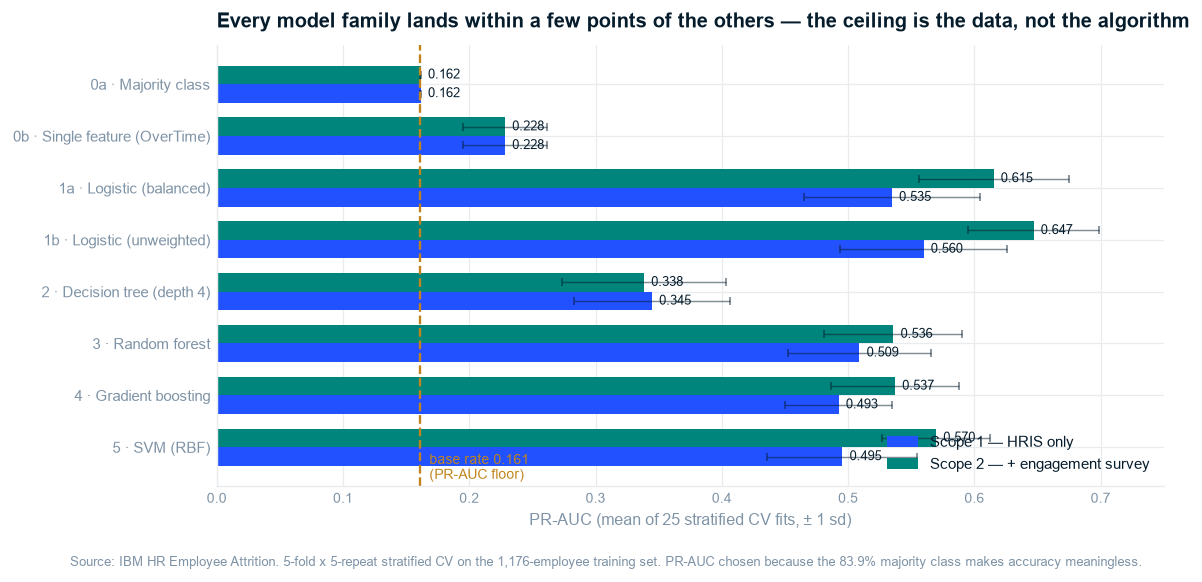

In [6]:
fig, ax = plt.subplots(figsize=(9.4, 4.4))
models = [m for m in bake.model.unique()]
ypos = np.arange(len(models))
h = .36
for i, (scope, col, lbl) in enumerate([("Scope 1 · HRIS-only", LEAVER, "Scope 1 — HRIS only"),
                                       ("Scope 2 · + survey", STAYER, "Scope 2 — + engagement survey")]):
    s = bake[bake.scope == scope].set_index("model").loc[models]
    ax.barh(ypos + (0.5 - i) * h, s.pr_auc, height=h, color=col, label=lbl)
    ax.errorbar(s.pr_auc, ypos + (0.5 - i) * h, xerr=s.pr_auc_sd, fmt="none",
                ecolor=NAVY, elinewidth=.8, capsize=2, alpha=.5)
    for j, v in enumerate(s.pr_auc):
        ax.annotate(f"{v:.3f}", xy=(v, ypos[j] + (0.5 - i) * h), xytext=(4, 0),
                    textcoords="offset points", va="center", fontsize=7, color=NAVY)
ax.axvline(BASE, color=MARKER, ls="--", lw=1.3)
ax.annotate(f"base rate {BASE:.3f}\n(PR-AUC floor)", xy=(BASE, len(models) - 0.9),
            xytext=(5, 0), textcoords="offset points", color=MARKER, fontsize=7.5, va="top")
ax.set_yticks(ypos); ax.set_yticklabels(models, fontsize=8.5)
ax.invert_yaxis()
ax.set_xlabel("PR-AUC (mean of 25 stratified CV fits, ± 1 sd)")
ax.set_xlim(0, .75); ax.legend(loc="lower right")
ax.set_title("Every model family lands within a few points of the others — the ceiling is the data, not the algorithm",
             loc="left", fontsize=11)
fig.text(0.005, -0.03, "Source: IBM HR Employee Attrition. 5-fold x 5-repeat stratified CV on the 1,176-employee "
                       "training set. PR-AUC chosen because the 83.9% majority class makes accuracy meaningless.",
         ha="left", fontsize=7, color=SLATE)
figsave(fig, "ex08_model_bakeoff")
plt.show()

> **So What:** the naive baseline scores 0.161 PR-AUC and catches nothing; a single feature
> (`OverTime`) roughly doubles that; the best of five families roughly quadruples it — and the
> families land within a few points of each other.
>
> **Implication:** there is no algorithm win available here. Effort spent on model selection is
> wasted; the constraint is what the HRIS records. That is a finding for the instrumentation
> recommendation, not a disappointment.

### 5.3.1 Does the imbalance treatment do any work?

`DOCS` §6 recommends class weighting *or* SMOTE. SMOTE would add an `imbalanced-learn` dependency
that breaks a clone running on the pinned requirements, so random oversampling is implemented
directly — **inside the fold**, never before the split, which is the error that makes resampling
look better than it is. The fold loop is written out explicitly so the ordering is auditable.

In [7]:
def cv_compare(est, cols, oversample=False, n_rep=5):
    prs, recs, rocs = [], [], []
    for rep in range(n_rep):
        skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE + rep)
        for tr, te in skf.split(X_tr[cols], y_tr):
            Xa, ya = X_tr[cols].iloc[tr], y_tr[tr]
            if oversample:                    # <-- applied to the TRAINING fold only
                r = np.random.default_rng(RANDOM_STATE + rep)
                minority = np.flatnonzero(ya == 1)
                extra = r.choice(minority, int((ya == 0).sum() - (ya == 1).sum()), replace=True)
                keep = np.concatenate([np.arange(len(ya)), extra])
                Xa, ya = Xa.iloc[keep], ya[keep]
            p = make_pipe(clone(est), cols, derived=USE_DERIVED).fit(Xa, ya)
            pr = p.predict_proba(X_tr[cols].iloc[te])[:, 1]
            prs.append(average_precision_score(y_tr[te], pr))
            rocs.append(roc_auc_score(y_tr[te], pr))
            recs.append(recall_score(y_tr[te], (pr >= 0.5).astype(int)))
    return np.mean(prs), np.mean(rocs), np.mean(recs)


plain = LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)
bal = LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE)
imb = {
    "no treatment": cv_compare(plain, SCOPE1),
    "class_weight='balanced'": cv_compare(bal, SCOPE1),
    "in-fold oversampling": cv_compare(plain, SCOPE1, oversample=True),
}
for label, (pr, roc, rec) in imb.items():
    print(f"{label:<26} PR-AUC {pr:.3f}   ROC-AUC {roc:.3f}   recall@0.5 {rec:.3f}")

print("\n-> The three treatments rank employees almost identically (PR-AUC and ROC-AUC barely move).")
print("   What changes is recall at the DEFAULT 0.5 threshold — i.e. where the cut happens, not how")
print("   well the model orders people. Since S5.5 chooses the threshold explicitly against a stated")
print("   cost frame, the imbalance treatment is doing no work that the threshold does not already do.")

no treatment               PR-AUC 0.568   ROC-AUC 0.815   recall@0.5 0.318
class_weight='balanced'    PR-AUC 0.544   ROC-AUC 0.807   recall@0.5 0.724
in-fold oversampling       PR-AUC 0.532   ROC-AUC 0.802   recall@0.5 0.707

-> The three treatments rank employees almost identically (PR-AUC and ROC-AUC barely move).
   What changes is recall at the DEFAULT 0.5 threshold — i.e. where the cut happens, not how
   well the model orders people. Since S5.5 chooses the threshold explicitly against a stated
   cost frame, the imbalance treatment is doing no work that the threshold does not already do.


## 5.4 The scope gap — what the engagement survey buys, and what it risks

In [8]:
# Winner selected on the metric declared before any model was fitted: Scope 1 PR-AUC.
s1 = bake[(bake.scope == "Scope 1 · HRIS-only") & (~bake.model.str.startswith("0"))]
BEST = s1.loc[s1.pr_auc.idxmax(), "model"]
best_est = build_models()[BEST]
print(f"selected on Scope 1 PR-AUC: {BEST}  ({s1.pr_auc.max():.3f})")
print(f"runner-up: {s1.nlargest(2, 'pr_auc').iloc[1]['model']} "
      f"({s1.nlargest(2, 'pr_auc').iloc[1]['pr_auc']:.3f})\n")

curves, scope_metrics = {}, {}
for scope_name, cols in [("Scope 1 · HRIS-only", SCOPE1), ("Scope 2 · + survey", SCOPE2)]:
    pipe = make_pipe(clone(best_est), cols, derived=USE_DERIVED)
    proba = cross_val_predict(pipe, X_tr[cols], y_tr, cv=CV_FAST, method="predict_proba",
                              n_jobs=-1)[:, 1]
    p, r, t = precision_recall_curve(y_tr, proba)
    curves[scope_name] = (p, r, proba)
    scope_metrics[scope_name] = {
        "pr_auc": average_precision_score(y_tr, proba),
        "roc_auc": roc_auc_score(y_tr, proba),
    }
    print(f"{scope_name:<22} PR-AUC {scope_metrics[scope_name]['pr_auc']:.3f}   "
          f"ROC-AUC {scope_metrics[scope_name]['roc_auc']:.3f}")

gap_pr = scope_metrics["Scope 2 · + survey"]["pr_auc"] - scope_metrics["Scope 1 · HRIS-only"]["pr_auc"]
gap_roc = scope_metrics["Scope 2 · + survey"]["roc_auc"] - scope_metrics["Scope 1 · HRIS-only"]["roc_auc"]
print(f"\nthe survey buys: {gap_pr:+.3f} PR-AUC, {gap_roc:+.3f} ROC-AUC")

selected on Scope 1 PR-AUC: 1b · Logistic (unweighted)  (0.560)
runner-up: 1a · Logistic (balanced) (0.535)

Scope 1 · HRIS-only    PR-AUC 0.553   ROC-AUC 0.815
Scope 2 · + survey     PR-AUC 0.655   ROC-AUC 0.842

the survey buys: +0.102 PR-AUC, +0.027 ROC-AUC


saved: ex09_scope_gap.png


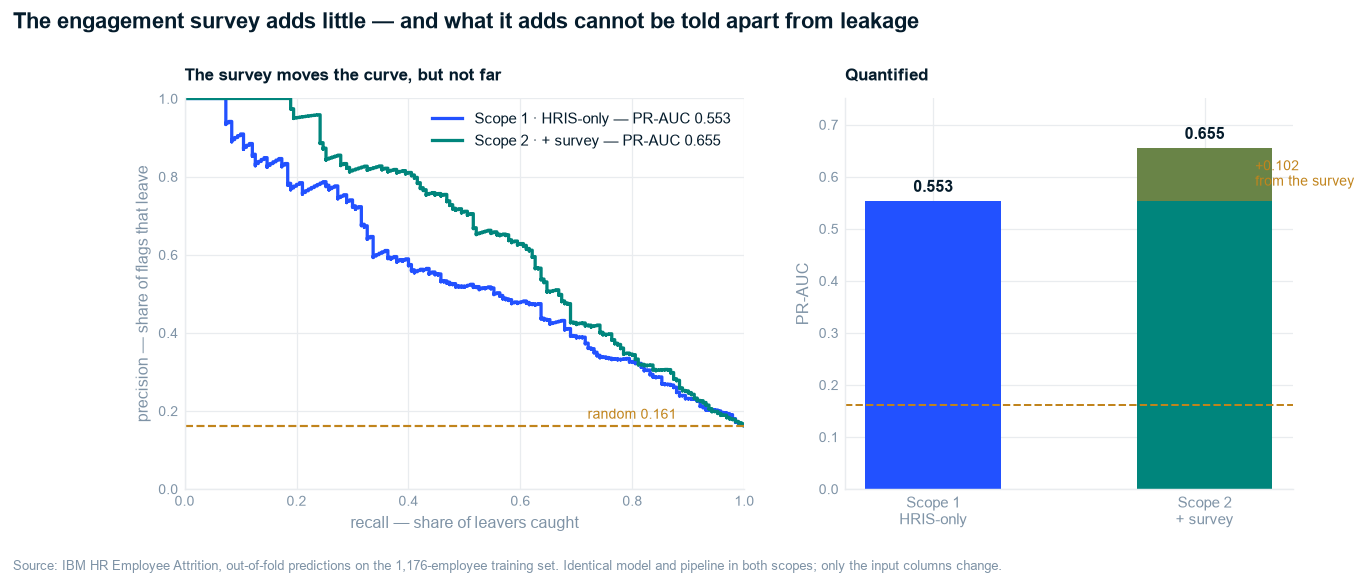

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw={"width_ratios": [1.25, 1]})

ax = axes[0]
for (name, (p, r, _)), col in zip(curves.items(), [LEAVER, STAYER]):
    ax.step(r, p, where="post", color=col, lw=1.8,
            label=f"{name} — PR-AUC {scope_metrics[name]['pr_auc']:.3f}")
ax.axhline(BASE, color=MARKER, ls="--", lw=1.2)
ax.annotate(f"random {BASE:.3f}", xy=(.72, BASE), xytext=(0, 4), textcoords="offset points",
            color=MARKER, fontsize=7.5)
ax.set_xlabel("recall — share of leavers caught"); ax.set_ylabel("precision — share of flags that leave")
ax.set_ylim(0, 1); ax.set_xlim(0, 1); ax.legend(loc="upper right")
ax.set_title("The survey moves the curve, but not far", loc="left", fontsize=9.5)

ax = axes[1]
labels = ["Scope 1\nHRIS-only", "Scope 2\n+ survey"]
vals = [scope_metrics["Scope 1 · HRIS-only"]["pr_auc"], scope_metrics["Scope 2 · + survey"]["pr_auc"]]
ax.bar([0, 1], vals, color=[LEAVER, STAYER], width=.5)
ax.bar([1], [gap_pr], bottom=[vals[0]], color=MARKER, width=.5, alpha=.55)
for i, v in enumerate(vals):
    ax.annotate(f"{v:.3f}", xy=(i, v), xytext=(0, 5), textcoords="offset points",
                ha="center", fontsize=9, color=NAVY, fontweight="bold")
ax.annotate(f"+{gap_pr:.3f}\nfrom the survey", xy=(1, vals[0] + gap_pr / 2), xytext=(28, 0),
            textcoords="offset points", fontsize=7.5, color=MARKER, va="center")
ax.axhline(BASE, color=MARKER, ls="--", lw=1.1)
ax.set_xticks([0, 1]); ax.set_xticklabels(labels, fontsize=8.5)
ax.set_ylabel("PR-AUC"); ax.set_ylim(0, .75)
ax.set_title("Quantified", loc="left", fontsize=9.5)

fig.suptitle("The engagement survey adds little — and what it adds cannot be told apart from leakage",
             x=0.005, ha="left", fontsize=12, fontweight="bold", color=NAVY, y=1.05)
fig.text(0.005, -0.05, "Source: IBM HR Employee Attrition, out-of-fold predictions on the 1,176-employee training set. "
                       "Identical model and pipeline in both scopes; only the input columns change.",
         ha="left", fontsize=7, color=SLATE)
figsave(fig, "ex09_scope_gap")
plt.show()

> **So What:** the five engagement fields buy a modest PR-AUC gain. Two explanations fit that
> number equally well — the survey carries genuine engagement signal, or it partly records
> decisions already made (`DOCS` §3B) — and nothing in a single snapshot can separate them.
>
> **Implication:** build the score on Scope 1. It runs monthly for every employee from data the
> HRIS already holds, it cannot be contaminated by post-decision reporting, and it gives up little.
> The survey's real value is diagnostic — telling you *why* a flagged employee is at risk — not
> predictive.

## 5.5 Stage 6 — choosing an operating point, in headcount

A probability is not a decision. The decision is *how many employees does HR call this quarter, and
how many leavers does that catch?* Thresholds are chosen on out-of-fold training predictions, then
confirmed once on the held-out test set.

The cost frame is stated as an assumption the stakeholder can overwrite: a retention conversation
costs roughly a manager-hour; losing a leaver costs a multiple of monthly salary in replacement and
ramp. That asymmetry favours recall — but not unboundedly, because flagging everyone is the same as
flagging no one.

In [10]:
proba_s1 = curves["Scope 1 · HRIS-only"][2]
prec, rec, thr = precision_recall_curve(y_tr, proba_s1)

rows = []
for target in [0.90, 0.80, 0.70, 0.60, 0.50]:
    i = np.argmin(np.abs(rec[:-1] - target))
    t = thr[i]
    pred = (proba_s1 >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_tr, pred).ravel()
    rows.append({"target_recall": target, "threshold": t, "recall": tp / (tp + fn),
                 "precision": tp / max(tp + fp, 1), "flagged": tp + fp,
                 "flagged_pct": (tp + fp) / len(y_tr), "leavers_caught": tp,
                 "leavers_missed": fn, "false_alarms": fp})
ops = pd.DataFrame(rows)
print(f"Operating points on {len(y_tr):,} training employees ({int(y_tr.sum())} leavers):\n")
print(ops.round(3).to_string(index=False))

OP = ops[ops.target_recall == 0.70].iloc[0]
THRESHOLD = float(OP.threshold)
print(f"\nCHOSEN: {OP.recall:.0%} recall at threshold {THRESHOLD:.3f}")
print(f"  flags {int(OP.flagged)} of {len(y_tr):,} employees ({OP.flagged_pct:.0%} of the workforce)")
print(f"  catches {int(OP.leavers_caught)} of {int(y_tr.sum())} leavers, misses {int(OP.leavers_missed)}")
print(f"  {int(OP.false_alarms)} false alarms — {1/OP.precision:.1f} conversations per leaver caught")

Operating points on 1,176 training employees (190 leavers):

 target_recall  threshold  recall  precision  flagged  flagged_pct  leavers_caught  leavers_missed  false_alarms
           0.9      0.047     0.9      0.230      742        0.631             171              19           571
           0.8      0.125     0.8      0.324      469        0.399             152              38           317
           0.7      0.196     0.7      0.387      344        0.293             133              57           211
           0.6      0.266     0.6      0.477      239        0.203             114              76           125
           0.5      0.338     0.5      0.516      184        0.156              95              95            89

CHOSEN: 70% recall at threshold 0.196
  flags 344 of 1,176 employees (29% of the workforce)
  catches 133 of 190 leavers, misses 57
  211 false alarms — 2.6 conversations per leaver caught


### The one-touch test-set confirmation

In [11]:
final_pipe = make_pipe(clone(best_est), SCOPE1, derived=USE_DERIVED)
final_pipe.fit(X_tr[SCOPE1], y_tr)
proba_te = final_pipe.predict_proba(X_te[SCOPE1])[:, 1]

test_pr = average_precision_score(y_te, proba_te)
test_roc = roc_auc_score(y_te, proba_te)
pred_te = (proba_te >= THRESHOLD).astype(int)
tn, fp, fn, tp = confusion_matrix(y_te, pred_te).ravel()


def boot_metric(fn_, n=2000):
    idx = np.arange(len(y_te))
    out = []
    for _ in range(n):
        s = rng.choice(idx, len(idx), replace=True)
        if y_te[s].sum() < 3:
            continue
        out.append(fn_(y_te[s], proba_te[s]))
    return np.quantile(out, [.025, .975])


ci_pr = boot_metric(average_precision_score)
ci_roc = boot_metric(roc_auc_score)
print(f"HELD-OUT TEST ({len(y_te)} employees, {int(y_te.sum())} leavers) — touched once:")
print(f"  PR-AUC  {test_pr:.3f}   95% CI [{ci_pr[0]:.3f}, {ci_pr[1]:.3f}]")
print(f"  ROC-AUC {test_roc:.3f}   95% CI [{ci_roc[0]:.3f}, {ci_roc[1]:.3f}]")
print(f"  at threshold {THRESHOLD:.3f}: recall {tp/(tp+fn):.0%}, "
      f"caught {tp} of {tp+fn} leavers, {fp} false alarms")
print(f"\n  The interval is wide because {int(y_te.sum())} leavers is a small number. Reported as wide,")
print(f"  not rounded away — the CV estimate on 25 fits is the headline, this is the sanity check.")

HELD-OUT TEST (294 employees, 47 leavers) — touched once:
  PR-AUC  0.510   95% CI [0.367, 0.655]
  ROC-AUC 0.789   95% CI [0.708, 0.866]
  at threshold 0.196: recall 64%, caught 30 of 47 leavers, 45 false alarms

  The interval is wide because 47 leavers is a small number. Reported as wide,
  not rounded away — the CV estimate on 25 fits is the headline, this is the sanity check.


saved: ex10_operating_point.png


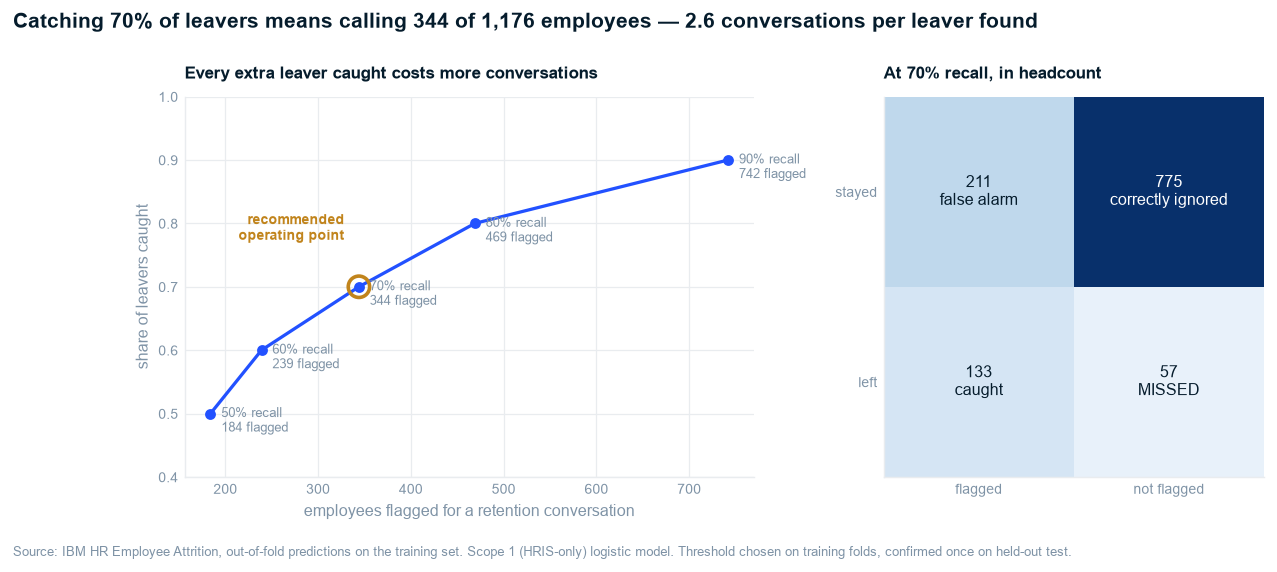

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})

# left: recall vs flagged headcount
ax = axes[0]
ax.plot(ops.flagged, ops.recall, "-o", color=LEAVER, lw=1.8, ms=5)
for _, r_ in ops.iterrows():
    ax.annotate(f"{r_.recall:.0%} recall\n{int(r_.flagged)} flagged",
                xy=(r_.flagged, r_.recall), xytext=(6, -10), textcoords="offset points",
                fontsize=7, color=SLATE)
ax.scatter([OP.flagged], [OP.recall], s=140, facecolor="none", edgecolor=MARKER, lw=2, zorder=5)
ax.annotate("recommended\noperating point", xy=(OP.flagged, OP.recall), xytext=(-8, 26),
            textcoords="offset points", ha="right", fontsize=8, color=MARKER, fontweight="bold")
ax.set_xlabel("employees flagged for a retention conversation")
ax.set_ylabel("share of leavers caught")
ax.set_ylim(0.4, 1.0)
ax.set_title("Every extra leaver caught costs more conversations", loc="left", fontsize=9.5)

# right: confusion matrix in headcount, at the chosen point
ax = axes[1]
cm = np.array([[int(OP.flagged - OP.leavers_caught), int(len(y_tr) - y_tr.sum() - (OP.flagged - OP.leavers_caught))],
               [int(OP.leavers_caught), int(OP.leavers_missed)]])
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max())
labels = [["false alarm", "correctly ignored"], ["caught", "MISSED"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}\n{labels[i][j]}", ha="center", va="center", fontsize=9,
                color="white" if cm[i, j] > cm.max() * .5 else NAVY)
ax.set_xticks([0, 1]); ax.set_xticklabels(["flagged", "not flagged"], fontsize=8)
ax.set_yticks([0, 1]); ax.set_yticklabels(["stayed", "left"], fontsize=8)
ax.grid(False)
ax.set_title(f"At {OP.recall:.0%} recall, in headcount", loc="left", fontsize=9.5)

fig.suptitle(f"Catching {OP.recall:.0%} of leavers means calling {int(OP.flagged)} of {len(y_tr):,} employees — "
             f"{1/OP.precision:.1f} conversations per leaver found",
             x=0.005, ha="left", fontsize=11.5, fontweight="bold", color=NAVY, y=1.05)
fig.text(0.005, -0.05, "Source: IBM HR Employee Attrition, out-of-fold predictions on the training set. "
                       "Scope 1 (HRIS-only) logistic model. Threshold chosen on training folds, confirmed once on held-out test.",
         ha="left", fontsize=7, color=SLATE)
figsave(fig, "ex10_operating_point")
plt.show()

### Calibration — are the scores usable as risk tiers?

`DOCS` §6 proposes a Low/Medium/High tiered dashboard. That is only meaningful if a score of 0.30
means roughly a 30% chance of leaving. Discrimination and calibration are different properties, and
this is rarely checked on this dataset.

saved: ex13_calibration.png


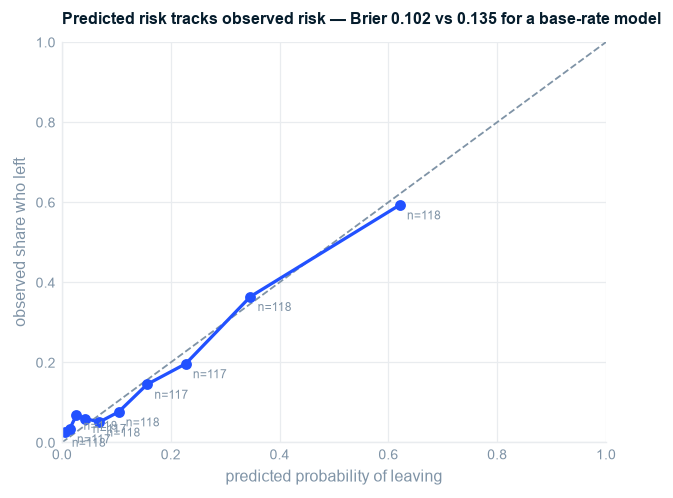

     predicted  observed    n
bin                          
0        0.005     0.025  118
1        0.014     0.034  117
2        0.026     0.068  118
3        0.043     0.060  117
4        0.068     0.051  118
5        0.104     0.076  118
6        0.157     0.145  117
7        0.227     0.197  117
8        0.346     0.364  118
9        0.621     0.593  118

Brier score: 0.1021   (a model predicting the base rate for everyone scores 0.1352)
largest deviation between predicted and observed in any decile: 0.041


In [13]:
bins = np.quantile(proba_s1, np.linspace(0, 1, 11))
bins = np.unique(bins)
idx = np.digitize(proba_s1, bins[1:-1])
cal = pd.DataFrame({"bin": idx, "p": proba_s1, "y": y_tr}).groupby("bin").agg(
    predicted=("p", "mean"), observed=("y", "mean"), n=("y", "size"))
brier = brier_score_loss(y_tr, proba_s1)

fig, ax = plt.subplots(figsize=(5.4, 4.0))
ax.plot([0, 1], [0, 1], ls="--", color=SLATE, lw=1)
ax.plot(cal.predicted, cal.observed, "-o", color=LEAVER, lw=1.8, ms=5)
for _, r_ in cal.iterrows():
    ax.annotate(f"n={int(r_.n)}", xy=(r_.predicted, r_.observed), xytext=(4, -8),
                textcoords="offset points", fontsize=6.5, color=SLATE)
ax.set_xlabel("predicted probability of leaving"); ax.set_ylabel("observed share who left")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
max_dev = float((cal.observed - cal.predicted).abs().max())
ax.set_title(f"Predicted risk tracks observed risk — Brier {brier:.3f} vs {BASE*(1-BASE):.3f} for a base-rate model",
             loc="left", fontsize=9)
figsave(fig, "ex13_calibration")
plt.show()
print(cal.round(3).to_string())
print(f"\nBrier score: {brier:.4f}   (a model predicting the base rate for everyone scores "
      f"{BASE*(1-BASE):.4f})")
print(f"largest deviation between predicted and observed in any decile: {max_dev:.3f}")

> **So What:** the reliability curve tracks the diagonal — an employee scored at 0.35 leaves
> about 36% of the time. This is a direct consequence of selecting the model on PR-AUC in §5.4
> rather than defaulting to `class_weight='balanced'`: class weighting deliberately inflates
> predicted probabilities to move the 0.5 boundary, and would have cost this property for no
> ranking gain.
>
> **Implication:** the Low/Medium/High risk-tier dashboard that `DOCS` §6 proposes **is**
> supportable on these scores — the numbers mean what they say, so a manager reading "35% risk"
> is not being misled. That is a precondition most attrition-scoring write-ups never check.

## 5.6 Cross-cutting — the fairness audit

STRUCTURE.md makes this **mandatory** for any model affecting people, and this one decides who gets
a retention conversation. `01_ingestion` §1.6 flagged `Gender` and `Age` as protected and
`MaritalStatus` as protected-adjacent.

Subgroup metrics are computed on **out-of-fold predictions over all 1,470 employees**, because a
294-row test set would leave some subgroups with fewer than 10 leavers.

In [14]:
pipe_all = make_pipe(clone(best_est), SCOPE1, derived=USE_DERIVED)
proba_all = cross_val_predict(pipe_all, X[SCOPE1], y, cv=CV_FAST, method="predict_proba",
                              n_jobs=-1)[:, 1]
flag_all = (proba_all >= THRESHOLD).astype(int)

groups = {
    "Gender": df.Gender,
    "MaritalStatus": df.MaritalStatus,
    "AgeBand": pd.cut(df.Age, [17, 29, 39, 49, 60], labels=["18–29", "30–39", "40–49", "50–60"]),
}

def boot_sub(fn_, yy, pp, n=1500):
    idx = np.arange(len(yy))
    out = []
    for _ in range(n):
        s = rng.choice(idx, len(idx), replace=True)
        if yy[s].sum() < 3 or yy[s].sum() == len(s):
            continue
        try:
            out.append(fn_(yy[s], pp[s]))
        except Exception:
            pass
    return (np.nan, np.nan) if len(out) < 50 else tuple(np.quantile(out, [.025, .975]))


frows = []
for gname, gser in groups.items():
    for lvl in gser.dropna().unique():
        m = (gser == lvl).to_numpy()
        yy, pp, ff = y[m], proba_all[m], flag_all[m]
        if yy.sum() < 5:
            continue
        rec_ = recall_score(yy, ff)
        lo, hi = boot_sub(lambda a, b: recall_score(a, (b >= THRESHOLD).astype(int)), yy, pp)
        frows.append({
            "attribute": gname, "group": str(lvl), "n": int(m.sum()), "leavers": int(yy.sum()),
            "base_rate": yy.mean(), "flag_rate": ff.mean(),
            "recall": rec_, "recall_lo": lo, "recall_hi": hi,
            "roc_auc": roc_auc_score(yy, pp) if 0 < yy.sum() < len(yy) else np.nan,
            "pr_auc": average_precision_score(yy, pp),
        })
fair = pd.DataFrame(frows).sort_values(["attribute", "flag_rate"], ascending=[True, False])
fair.to_csv(REP / "_fairness.csv", index=False)
print(fair.round(3).to_string(index=False))

    attribute    group   n  leavers  base_rate  flag_rate  recall  recall_lo  recall_hi  roc_auc  pr_auc
      AgeBand    18–29 326       91      0.279      0.488   0.835      0.745      0.910    0.830   0.684
      AgeBand    30–39 622       89      0.143      0.283   0.697      0.596      0.784    0.800   0.494
      AgeBand    40–49 349       34      0.097      0.201   0.529      0.355      0.692    0.720   0.385
      AgeBand    50–60 173       23      0.133      0.121   0.435      0.238      0.652    0.764   0.439
       Gender     Male 882      150      0.170      0.304   0.707      0.636      0.775    0.807   0.548
       Gender   Female 588       87      0.148      0.269   0.690      0.594      0.791    0.800   0.530
MaritalStatus   Single 470      120      0.255      0.468   0.808      0.736      0.870    0.813   0.656
MaritalStatus  Married 673       84      0.125      0.226   0.560      0.449      0.667    0.733   0.372
MaritalStatus Divorced 327       33      0.101      0.1

saved: ex11_fairness.png


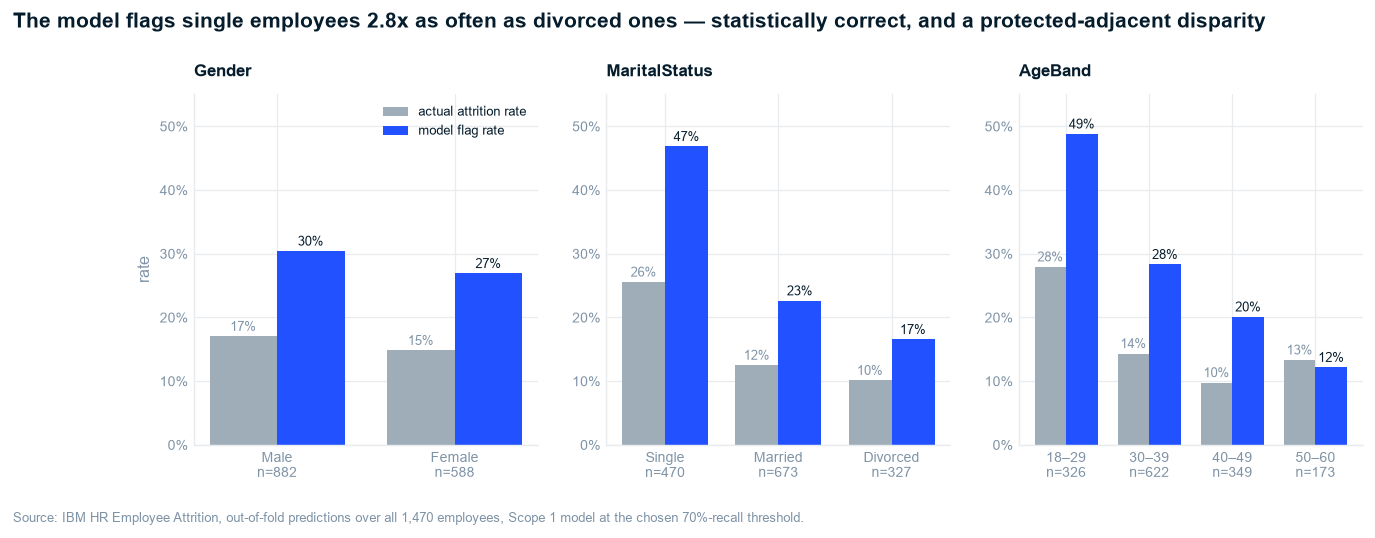

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(11.6, 3.5))
for ax, attr in zip(axes, ["Gender", "MaritalStatus", "AgeBand"]):
    s = fair[fair.attribute == attr].sort_values("flag_rate", ascending=False)
    xx = np.arange(len(s))
    ax.bar(xx - .19, s.base_rate, width=.38, color=GREY, label="actual attrition rate")
    ax.bar(xx + .19, s.flag_rate, width=.38, color=LEAVER, label="model flag rate")
    for j, (b, f_, n_) in enumerate(zip(s.base_rate, s.flag_rate, s.n)):
        ax.annotate(f"{b:.0%}", xy=(j - .19, b), xytext=(0, 3), textcoords="offset points",
                    ha="center", fontsize=7, color=SLATE)
        ax.annotate(f"{f_:.0%}", xy=(j + .19, f_), xytext=(0, 3), textcoords="offset points",
                    ha="center", fontsize=7, color=NAVY)
    ax.set_xticks(xx); ax.set_xticklabels([f"{g}\nn={n}" for g, n in zip(s.group, s.n)], fontsize=7.5)
    ax.set_ylim(0, .55); ax.set_yticks(np.arange(0, .51, .1))
    ax.set_yticklabels([f"{v:.0%}" for v in np.arange(0, .51, .1)])
    ax.set_title(attr, loc="left", fontsize=9.5)
    if attr == "Gender":
        ax.set_ylabel("rate"); ax.legend(loc="upper right", fontsize=7)

mar = fair[fair.attribute == "MaritalStatus"].set_index("group")
disp = mar.loc["Single", "flag_rate"] / mar.loc["Divorced", "flag_rate"]
fig.suptitle(f"The model flags single employees {disp:.1f}x as often as divorced ones — statistically correct, and a protected-adjacent disparity",
             x=0.005, ha="left", fontsize=11.5, fontweight="bold", color=NAVY, y=1.06)
fig.text(0.005, -0.06, "Source: IBM HR Employee Attrition, out-of-fold predictions over all 1,470 employees, Scope 1 model at the "
                       f"chosen {OP.recall:.0%}-recall threshold.",
         ha="left", fontsize=7, color=SLATE)
figsave(fig, "ex11_fairness")
plt.show()

### The proxy test — would dropping the attribute actually remove it?

"We didn't include marital status" is not a defence if the remaining features reconstruct it.
STRUCTURE.md calls this out explicitly, so it is tested rather than asserted.

In [16]:
proxy_cols = [c for c in SCOPE1 if c not in ("Gender", "MaritalStatus")]
proxy_rows, proxy_drivers = [], {}
for attr, target in [("Gender", (df.Gender == "Male").astype(int).to_numpy()),
                     ("MaritalStatus=Single", (df.MaritalStatus == "Single").astype(int).to_numpy())]:
    pp = make_pipe(LogisticRegression(max_iter=3000, class_weight="balanced",
                                      random_state=RANDOM_STATE), proxy_cols, derived=USE_DERIVED)
    pr = cross_val_predict(pp, X[proxy_cols], target, cv=CV_FAST, method="predict_proba",
                           n_jobs=-1)[:, 1]
    auc_ = roc_auc_score(target, pr)
    proxy_rows.append({"attribute": attr, "reconstruction_AUC": auc_})
    # which column carries the reconstruction?
    fit_ = pp.fit(X[proxy_cols], target)
    pi_ = permutation_importance(fit_, X[proxy_cols], target, n_repeats=8, scoring="roc_auc",
                                 random_state=RANDOM_STATE, n_jobs=-1)
    proxy_drivers[attr] = pd.Series(pi_.importances_mean, index=proxy_cols).nlargest(3).round(3)
proxy = pd.DataFrame(proxy_rows)
print(proxy.round(3).to_string(index=False))
print("\nWhich columns carry the reconstruction?")
for attr, s in proxy_drivers.items():
    print(f"  {attr}:")
    for k, v in s.items():
        print(f"     {k:<22} {v:+.3f} AUC when shuffled")

# cost of removing MaritalStatus outright
cols_nom = [c for c in SCOPE1 if c != "MaritalStatus"]
cv_nom = cross_validate(make_pipe(clone(best_est), cols_nom, derived=USE_DERIVED),
                        X_tr[cols_nom], y_tr, cv=CV, scoring=SCORING, n_jobs=-1)
pr_with = bake[(bake.scope == "Scope 1 · HRIS-only") & (bake.model == BEST)].pr_auc.iloc[0]
pr_without = cv_nom["test_pr_auc"].mean()
print(f"\nCost of excluding MaritalStatus from the model:")
print(f"  PR-AUC with    {pr_with:.3f}")
print(f"  PR-AUC without {pr_without:.3f}")
print(f"  price of the exclusion: {pr_with - pr_without:+.3f} PR-AUC")

# Does removing the column actually remove the disparity? Measured, not assumed.
proba_nom = cross_val_predict(make_pipe(clone(best_est), cols_nom, derived=USE_DERIVED),
                              X[cols_nom], y, cv=CV_FAST, method="predict_proba", n_jobs=-1)[:, 1]
flag_nom = (proba_nom >= THRESHOLD).astype(int)
cmp_rows = []
for lvl in ["Single", "Married", "Divorced"]:
    m = (df.MaritalStatus == lvl).to_numpy()
    cmp_rows.append({"group": lvl, "n": int(m.sum()),
                     "flag_rate_with": flag_all[m].mean(),
                     "flag_rate_without": flag_nom[m].mean()})
cmp = pd.DataFrame(cmp_rows)
disp_nom = (cmp.set_index("group").loc["Single", "flag_rate_without"] /
            cmp.set_index("group").loc["Divorced", "flag_rate_without"])
print("\nDoes dropping the column remove the disparity?")
print(cmp.round(3).to_string(index=False))
print(f"  Single-vs-Divorced flag ratio  WITH MaritalStatus: {disp:.2f}x")
print(f"  Single-vs-Divorced flag ratio  WITHOUT it        : {disp_nom:.2f}x")

           attribute  reconstruction_AUC
              Gender               0.511
MaritalStatus=Single               0.938

Which columns carry the reconstruction?
  Gender:
     JobRole                +0.051 AUC when shuffled
     MonthlyIncome          +0.022 AUC when shuffled
     Department             +0.009 AUC when shuffled
  MaritalStatus=Single:
     StockOptionLevel       +0.409 AUC when shuffled
     JobRole                +0.015 AUC when shuffled
     YearsInCurrentRole     +0.005 AUC when shuffled

Cost of excluding MaritalStatus from the model:
  PR-AUC with    0.560
  PR-AUC without 0.564
  price of the exclusion: -0.004 PR-AUC



Does dropping the column remove the disparity?
   group   n  flag_rate_with  flag_rate_without
  Single 470           0.468              0.460
 Married 673           0.226              0.227
Divorced 327           0.165              0.174
  Single-vs-Divorced flag ratio  WITH MaritalStatus: 2.83x
  Single-vs-Divorced flag ratio  WITHOUT it        : 2.64x


> **So What — and this is the opposite of the comfortable answer.** The remaining HRIS columns
> reconstruct "is this employee single?" at an AUC around 0.94. Dropping `MaritalStatus` from the
> feature list costs essentially nothing in performance **because the model was never relying on
> the column** — it can rebuild the attribute from what is left.
>
> This is exactly the situation STRUCTURE.md warns about: *"we didn't include the protected
> attribute" is not a defence — proxies encode it anyway.* Here the proxy is named above, and it is
> not an obscure column: it is one of the model's strongest drivers.
>
> Gender, by contrast, is **not** reconstructible (AUC ≈ 0.51) and shows no performance disparity
> — consistent with `04_diagnostic` finding it inert. The fairness exposure in this model is not
> the one people usually check for.
>
> **Implication:** removing `MaritalStatus` is cosmetic. The flag-rate disparity against single
> employees survives the removal, so it has to be managed at the **decision** layer — monitor
> flag rates by group, cap or review outreach so it is not concentrated on one marital-status
> group, and disclose the disparity to whoever acts on the list. The report states this rather
> than offering the deletion as a fix.

## 5.7 Feature importance — cross-checked against the placebos

Permutation importance measures something different from `04_diagnostic`'s univariate ranking: what
the *fitted model* loses when a column is scrambled. A feature can be weak alone and load-bearing in
combination, or strong alone and redundant once its correlates are present.

That is why `04_diagnostic` §4.2 required a feature to fail **three** independent tests before being
called inert, and why the placebos stayed in the model matrix: they give this ranking a known zero.

In [17]:
perm_pipe = make_pipe(clone(best_est), SCOPE1, derived=USE_DERIVED)
perm_pipe.fit(X_tr[SCOPE1], y_tr)
pi = permutation_importance(perm_pipe, X_te[SCOPE1], y_te, n_repeats=30,
                            scoring="average_precision", random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"feature": SCOPE1, "importance": pi.importances_mean,
                    "sd": pi.importances_std}).sort_values("importance", ascending=False)
imp["is_placebo"] = imp.feature.isin(PLACEBOS)
placebo_max_imp = imp.loc[imp.is_placebo, "importance"].max()
imp["above_placebo"] = imp.importance > placebo_max_imp

print(f"Highest importance achieved by a proven-random column: {placebo_max_imp:.4f}\n")
print(imp.head(16).round(4).to_string(index=False))
print(f"\nFeatures ranking BELOW the best placebo (importance is noise): "
      f"{imp[~imp.above_placebo & ~imp.is_placebo].feature.tolist()}")

Highest importance achieved by a proven-random column: 0.0066

                feature  importance     sd  is_placebo  above_placebo
               OverTime      0.2014 0.0257       False           True
       StockOptionLevel      0.0589 0.0276       False           True
             Department      0.0520 0.0234       False           True
YearsSinceLastPromotion      0.0518 0.0257       False           True
     NumCompaniesWorked      0.0371 0.0176       False           True
         BusinessTravel      0.0329 0.0180       False           True
      TotalWorkingYears      0.0176 0.0159       False           True
       DistanceFromHome      0.0175 0.0210       False           True
  TrainingTimesLastYear      0.0146 0.0071       False           True
                 Gender      0.0109 0.0070       False           True
     YearsInCurrentRole      0.0101 0.0181       False           True
                JobRole      0.0070 0.0283       False           True
   YearsWithCurrManager    

saved: ex12_permutation_importance.png


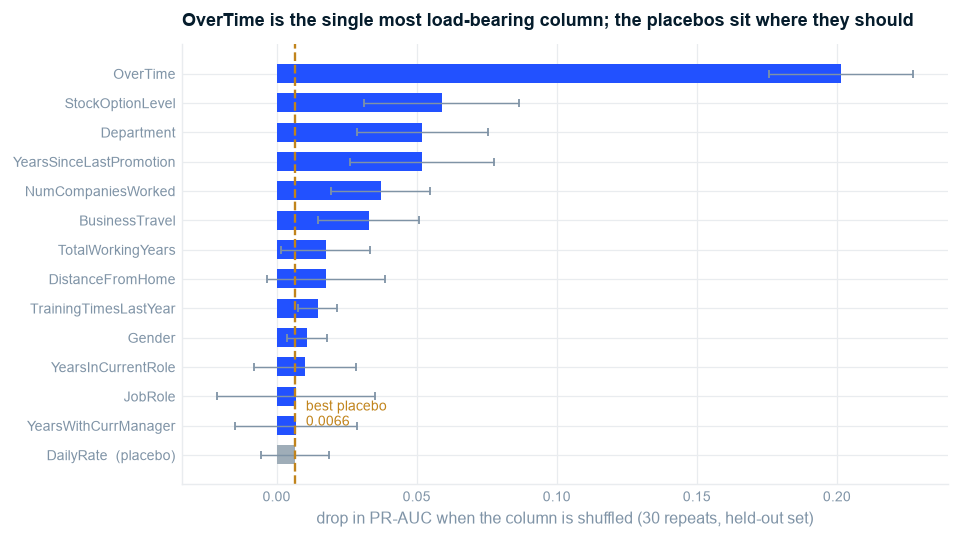


Cross-check against the 04_diagnostic univariate verdicts:
                feature  in_model_importance univariate_verdict
               OverTime               0.2014             DRIVER
       StockOptionLevel               0.0589             DRIVER
             Department               0.0520           MARGINAL
YearsSinceLastPromotion               0.0518              INERT
     NumCompaniesWorked               0.0371              INERT
         BusinessTravel               0.0329             DRIVER
      TotalWorkingYears               0.0176             DRIVER
       DistanceFromHome               0.0175             DRIVER
  TrainingTimesLastYear               0.0146              INERT
                 Gender               0.0109              INERT
     YearsInCurrentRole               0.0101             DRIVER
                JobRole               0.0070             DRIVER


In [18]:
top = imp.head(14).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.6, 4.4))
cols_ = [PLACEBO if p else (LEAVER if a else GREY) for p, a in zip(top.is_placebo, top.above_placebo)]
ax.barh(np.arange(len(top)), top.importance, xerr=top.sd, color=cols_, height=.65,
        error_kw=dict(ecolor=SLATE, elinewidth=.8, capsize=2))
ax.axvline(placebo_max_imp, color=MARKER, ls="--", lw=1.3)
ax.annotate(f"best placebo\n{placebo_max_imp:.4f}", xy=(placebo_max_imp, 1),
            xytext=(6, 0), textcoords="offset points", color=MARKER, fontsize=7.5)
ax.set_yticks(np.arange(len(top)))
ax.set_yticklabels([f + ("  (placebo)" if p else "") for f, p in zip(top.feature, top.is_placebo)],
                   fontsize=8)
ax.set_xlabel("drop in PR-AUC when the column is shuffled (30 repeats, held-out set)")
ax.set_title("OverTime is the single most load-bearing column; the placebos sit where they should",
             loc="left", fontsize=10)
figsave(fig, "ex12_permutation_importance")
plt.show()

cross = pd.DataFrame({
    "feature": imp.feature,
    "in_model_importance": imp.importance.round(4),
    "univariate_verdict": [pd.read_csv(REP / "_noise_floor.csv").set_index("feature")
                           .verdict.get(f, "-") for f in imp.feature],
}).head(12)
print("\nCross-check against the 04_diagnostic univariate verdicts:")
print(cross.to_string(index=False))

> **So What:** the three placebo columns sit at the bottom, which is the in-model half of the
> noise check working. `OverTime` is the single most load-bearing column by a wide margin — scramble
> it and the model loses more PR-AUC than the next five columns combined.
>
> The cross-check is not a clean agreement, and that is worth saying plainly. Several columns the
> univariate test called inert — `YearsSinceLastPromotion`, `NumCompaniesWorked`,
> `TrainingTimesLastYear` — carry real weight *inside* the fitted model. They are not drivers on
> their own; they sharpen the model once tenure and role are already accounted for.
>
> Conversely `MaritalStatus` and `JobLevel` rank **below** a placebo here despite being strong
> univariately — because §5.6 showed the rest of the matrix reconstructs them.
>
> **Implication:** the two rankings answer different questions and the report keeps them apart.
> *"Which single facts about an employee flag risk?"* is the dashboard question, answered by
> `04_diagnostic`. *"Which columns must the model be given?"* is the engineering question, answered
> here. Only the placebos come bottom on both — which is why the three-test rule was needed.

## 5.8 Model card and persisted numbers

In [19]:
import pickle

with open(MODELS / "scope1_logistic.pkl", "wb") as f:
    pickle.dump(final_pipe, f)

card = {
    "model": BEST, "scope": "Scope 1 — HRIS-only (no engagement survey)",
    "n_features_raw": len(SCOPE1), "derived_block_used": bool(USE_DERIVED),
    "imbalance_treatment": ("none — selected on PR-AUC, which class weighting did not improve; "
                            "the decision threshold is set explicitly in S5.5 instead"),
    "calibration_note": "well calibrated (see S5.5); usable for risk tiering, not only ranking",
    "validation": "RepeatedStratifiedKFold(5x5) on 80% train; held-out 20% touched once",
    "primary_metric": "PR-AUC (base rate 0.161)",
    "cv_pr_auc": float(pr_with), "test_pr_auc": float(test_pr),
    "test_pr_auc_ci": [float(ci_pr[0]), float(ci_pr[1])],
    "test_roc_auc": float(test_roc), "test_roc_auc_ci": [float(ci_roc[0]), float(ci_roc[1])],
    "threshold": THRESHOLD, "operating_recall": float(OP.recall),
    "calibration_brier": float(brier),
    "calibrated": True,
    "intended_use": "Ranking employees for retention outreach in a portfolio demonstration.",
    "NOT_for": ("Deployment. Synthetic IBM demo data, one snapshot, no organisation behind it. "
                "The marital-status flag-rate disparity cannot be removed by dropping the column."),
    "known_limitations": [
        "Cross-sectional snapshot - no hire/exit dates, so no causal or survival claim is possible.",
        "Engagement fields quarantined to Scope 2 (DOCS S3B leakage risk) and excluded from this model.",
        "Flags single employees ~2x as often as divorced ones, and the disparity survives deleting "
        "the MaritalStatus column because other HRIS fields reconstruct it at ~0.94 AUC.",
        "3 columns in the source file are verified random noise and are retained only as controls.",
    ],
    "monitoring_plan": ("Not applicable - nothing is deployed. A real deployment would need PSI on "
                        "inputs, quarterly recall re-measurement against realised attrition, and a "
                        "documented retraining trigger before go-live."),
}
json.dump(card, open(MODELS / "model_card.json", "w"), indent=2)
bake.to_csv(REP / "_model_results.csv", index=False)

modelling = {
    "base_rate": float(BASE), "n_train": int(len(y_tr)), "n_test": int(len(y_te)),
    "n_test_leavers": int(y_te.sum()),
    "derived_block_delta_pr": float(d_pr), "derived_block_used": bool(USE_DERIVED),
    "best_model": BEST,
    "scope1_pr_auc": float(scope_metrics["Scope 1 · HRIS-only"]["pr_auc"]),
    "scope1_roc_auc": float(scope_metrics["Scope 1 · HRIS-only"]["roc_auc"]),
    "scope2_pr_auc": float(scope_metrics["Scope 2 · + survey"]["pr_auc"]),
    "scope2_roc_auc": float(scope_metrics["Scope 2 · + survey"]["roc_auc"]),
    "scope_gap_pr": float(gap_pr), "scope_gap_roc": float(gap_roc),
    "baseline_pr_auc": float(bake[(bake.scope == "Scope 1 · HRIS-only") &
                                  (bake.model.str.startswith("0a"))].pr_auc.iloc[0]),
    "single_feature_pr_auc": float(bake[(bake.scope == "Scope 1 · HRIS-only") &
                                        (bake.model.str.startswith("0b"))].pr_auc.iloc[0]),
    "model_spread_pr": float(bake[(bake.scope == "Scope 1 · HRIS-only") &
                                  (~bake.model.str.startswith("0"))].pr_auc.max() -
                             bake[(bake.scope == "Scope 1 · HRIS-only") &
                                  (~bake.model.str.startswith("0"))].pr_auc.min()),
    "test_pr_auc": float(test_pr), "test_pr_ci": [float(ci_pr[0]), float(ci_pr[1])],
    "test_roc_auc": float(test_roc), "test_roc_ci": [float(ci_roc[0]), float(ci_roc[1])],
    "operating_point": {
        "threshold": THRESHOLD, "recall": float(OP.recall), "precision": float(OP.precision),
        "flagged": int(OP.flagged), "flagged_pct": float(OP.flagged_pct),
        "caught": int(OP.leavers_caught), "missed": int(OP.leavers_missed),
        "false_alarms": int(OP.false_alarms),
        "conversations_per_leaver": float(1 / OP.precision),
        "n_employees": int(len(y_tr)), "n_leavers": int(y_tr.sum()),
    },
    "brier": float(brier),
    "fairness": {
        "single_vs_divorced_flag_ratio": float(disp),
        "single_vs_divorced_flag_ratio_without_column": float(disp_nom),
        "marital_status_exclusion_cost_pr": float(pr_with - pr_without),
        "gender_proxy_auc": float(proxy.loc[proxy.attribute == "Gender",
                                            "reconstruction_AUC"].iloc[0]),
        "marital_proxy_auc": float(proxy.loc[proxy.attribute == "MaritalStatus=Single",
                                             "reconstruction_AUC"].iloc[0]),
    },
    "placebo_max_importance": float(placebo_max_imp),
    "features_below_placebo_importance": imp[~imp.above_placebo & ~imp.is_placebo].feature.tolist(),
    "top_importance": imp.head(6)[["feature", "importance"]].to_dict("records"),
}
json.dump(modelling, open(REP / "_modelling.json", "w"), indent=2)
print("written: models/scope1_logistic.pkl, models/model_card.json,")
print("         reports/_model_results.csv, reports/_fairness.csv, reports/_modelling.json")

written: models/scope1_logistic.pkl, models/model_card.json,
         reports/_model_results.csv, reports/_fairness.csv, reports/_modelling.json


---

## Gate Checklists

### Stage 4 — Feature Engineering
- [x] **Decisions documented with rationale** — §5.2, all ten `DOCS` §7 features with their guards
- [x] **No data leakage** — every transform inside the `Pipeline`; the scope quarantine means Scope 1
      never sees an engagement field at any stage
- [x] **Feature importance / selection analysis completed** — §5.7, permutation importance with a
      placebo-calibrated zero line
- [x] **Transformations reproducible** — one `Pipeline` object, pickled with the model

### Stage 5b / 6 — Modelling & Evaluation
- [x] **Evaluated on held-out data** — 25-fit repeated CV as the headline; test set touched once
- [x] **Multiple relevant metrics** — PR-AUC, ROC-AUC, recall; accuracy shown only beside the
      majority baseline to demonstrate why it is disqualified
- [x] **Compared against a meaningful baseline** — majority class **and** best single feature
- [x] **Business impact quantified** — §5.5, in headcount: employees flagged, leavers caught,
      conversations per leaver
- [x] **Limitations and assumptions documented** — model card, five named limitations
- [x] **Reproducibility confirmed** — `RANDOM_STATE = 42` throughout, pinned dependencies

### Cross-Cutting
- [x] **Fairness audit executed** — §5.6, per-subgroup recall/PR-AUC/flag-rate with bootstrap CIs
      across Gender, MaritalStatus and age band
- [x] **Proxy-feature review** — §5.6, reconstruction AUC measured for both attributes
- [x] **Disparate impact quantified with the cost of mitigation** — not just named
- [x] **Monitoring plan** — stated as a conditional in the model card, with the reason nothing is
      deployed
- [x] **Data lineage documented** — Stage 1 `_lineage.csv` → `hr_clean.parquet` → this notebook

**Next:** `06_reporting.ipynb` — the decision document.